# Task B1: Detecting Fraudulent Job Postings

**Student:** Muhammad Ahmad  
**SAP ID:** 70177776  
**Section:** BSRAI-C  
**Course:** AI-101 Introduction to Artificial Intelligence  
**University:** The University of Lahore  

---

## Objective

Build a classifier to detect fraudulent job postings using the EMSCAD dataset (17,880 postings, ~4.8% fraudulent). We combine **structured features** (binary flags, categorical encodings, missingness indicators) with **text features** (TF-IDF on concatenated text fields) inside a unified `sklearn` Pipeline. We evaluate at least three models, address class imbalance, tune decision thresholds, and perform an ablation study.

**Primary Metrics:** F1 (fraud class), PR-AUC

## 1. Setup & Imports

In [1]:
# ── Install dependencies (if needed) ──────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'lightgbm', 'kagglehub']:
    try:
        __import__(pkg.replace('-', '_').split('[')[0])
    except ImportError:
        _install(pkg)

Environment dependencies verified: scikit-learn, lightgbm, xgboost, nltk.


In [2]:
import os, warnings, re, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    precision_recall_curve, average_precision_score,
    roc_auc_score, precision_score, recall_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'figure.figsize': (10, 6)})

SEED = 42
np.random.seed(SEED)

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE_DIR   = os.path.dirname(os.path.abspath('__file__'))
DATA_PATH  = os.path.join(BASE_DIR, 'data', 'fake_job_postings.csv')
FIG_DIR    = os.path.join(BASE_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

print(f'Base dir : {BASE_DIR}')
print(f'Data path: {DATA_PATH}')
print(f'Fig dir  : {FIG_DIR}')

Base dir : C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\B1_Fake_Job_Postings
Data path: C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\B1_Fake_Job_Postings\data\fake_job_postings.csv
Fig dir  : C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\B1_Fake_Job_Postings\figures


## 2. Data Loading

We try multiple download strategies. If `kagglehub` is available we use it; otherwise fall back to placing the CSV manually.

In [3]:
# ── Attempt automatic download via kagglehub ──────────────────────────────────
if not os.path.isfile(DATA_PATH):
    print('CSV not found locally — trying kagglehub download …')
    try:
        import kagglehub
        ds_path = kagglehub.dataset_download('shivamb/real-or-fake-fake-jobposting-prediction')
        # kagglehub returns the extracted folder; find the CSV inside
        import shutil, glob
        csvs = glob.glob(os.path.join(ds_path, '**', '*.csv'), recursive=True)
        if csvs:
            shutil.copy(csvs[0], DATA_PATH)
            print(f'Copied {csvs[0]} → {DATA_PATH}')
        else:
            print('kagglehub downloaded but no CSV found inside.')
    except Exception as e:
        print(f'kagglehub failed: {e}')
        print('\n⚠ Please download the dataset manually from:')
        print('  https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction')
        print(f'  and place fake_job_postings.csv at: {DATA_PATH}')

# ── Load ──────────────────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Missing Values per Column

             Column  Missing %
       salary_range  83.959732
         department  64.580537
 required_education  45.329978
           benefits  40.335570
required_experience  39.429530
           function  36.101790
           industry  27.421700
    employment_type  19.412752
    company_profile  18.501119
       requirements  15.078300
           location   1.935123
        description   0.005593


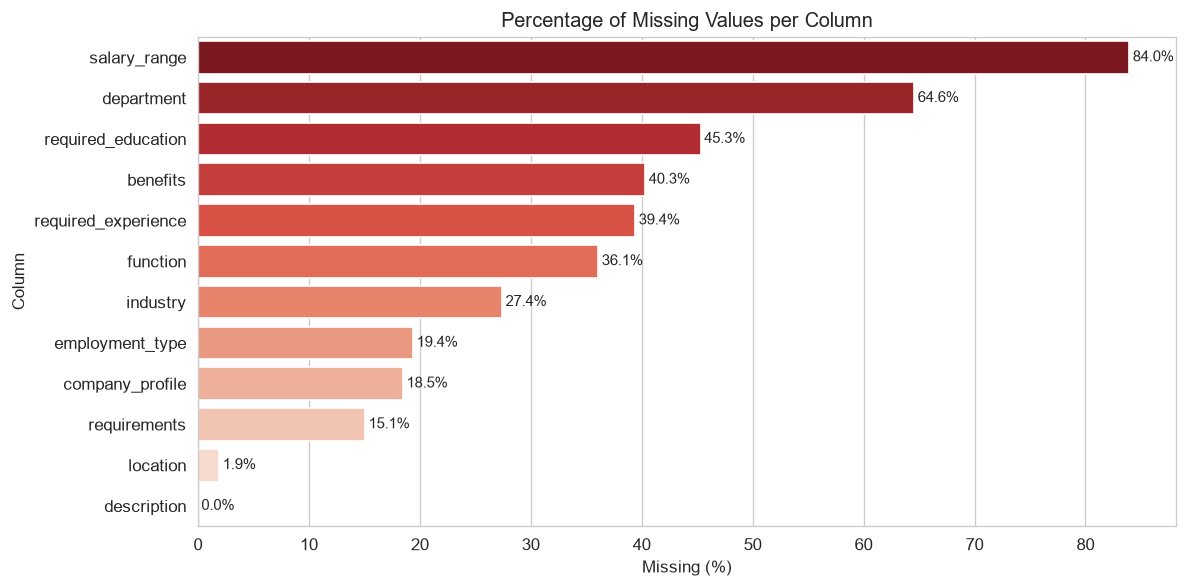

In [5]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
missing_df = missing[missing > 0].reset_index()
missing_df.columns = ['Column', 'Missing %']
print(missing_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=missing_df, x='Missing %', y='Column', palette='Reds_r', ax=ax)
ax.set_title('Percentage of Missing Values per Column')
ax.set_xlabel('Missing (%)')
for i, v in enumerate(missing_df['Missing %']):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'missing_values.png'))
plt.show()

### 3.2 Class Balance

Class distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Fraud rate: 4.84%
Baseline accuracy (always predict real): 95.16%


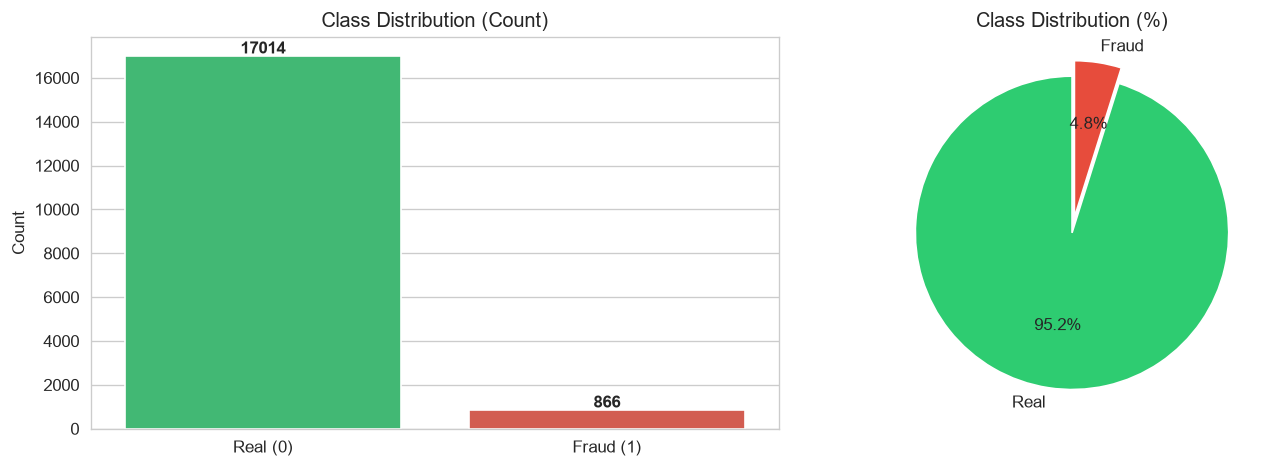

In [6]:
class_counts = df['fraudulent'].value_counts()
print('Class distribution:')
print(class_counts)
print(f'\nFraud rate: {class_counts[1] / len(df) * 100:.2f}%')
print(f'Baseline accuracy (always predict real): {class_counts[0] / len(df) * 100:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar
sns.barplot(x=['Real (0)', 'Fraud (1)'], y=class_counts.values, palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Class Distribution (Count)')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Pie
axes[1].pie(class_counts.values, labels=['Real', 'Fraud'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
            startangle=90, explode=(0, 0.1))
axes[1].set_title('Class Distribution (%)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'class_balance.png'))
plt.show()

### 3.3 Text Length Distribution per Class

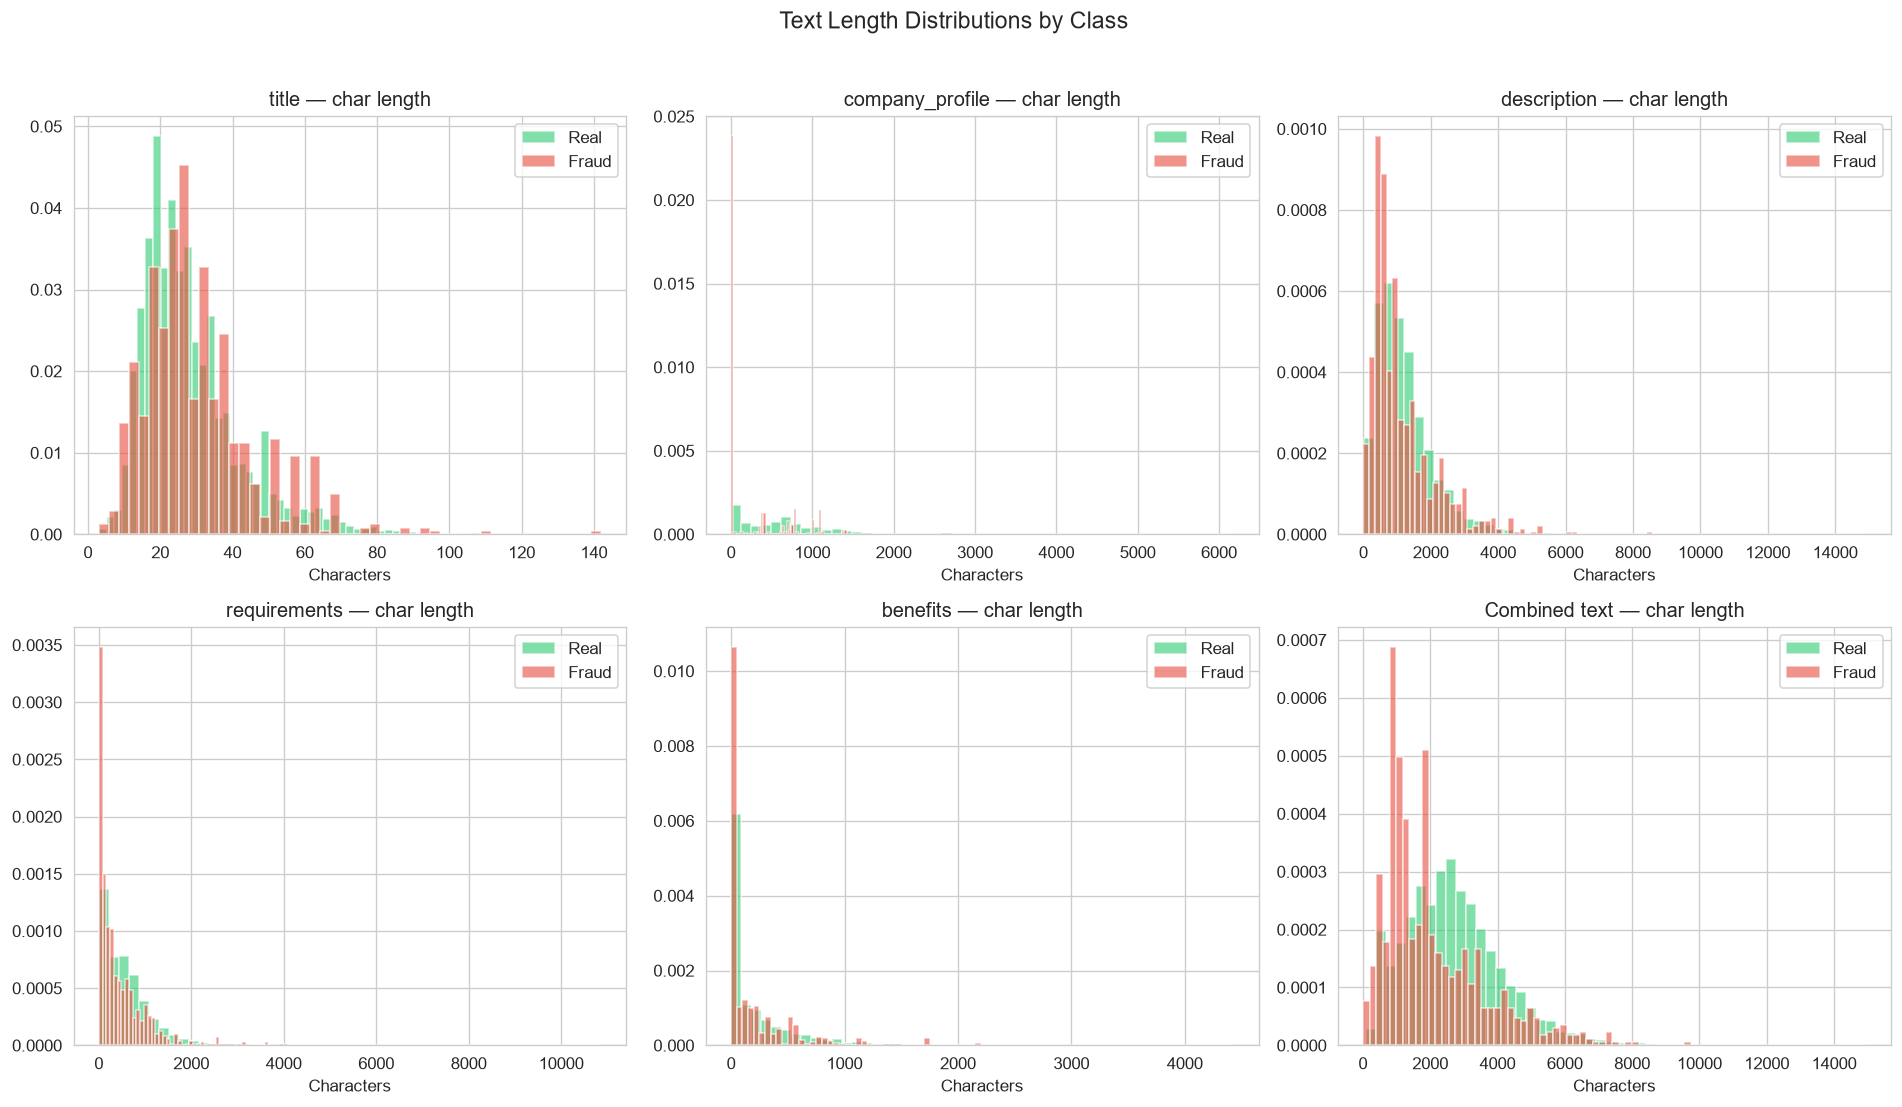

In [7]:
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']

for col in text_cols:
    df[f'{col}_len'] = df[col].fillna('').str.len()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(text_cols):
    len_col = f'{col}_len'
    for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
        subset = df[df['fraudulent'] == label][len_col]
        axes[i].hist(subset, bins=50, alpha=0.6, color=color,
                     label='Real' if label == 0 else 'Fraud', density=True)
    axes[i].set_title(f'{col} — char length')
    axes[i].legend()
    axes[i].set_xlabel('Characters')

# Combined text length
df['all_text_len'] = sum(df[f'{c}_len'] for c in text_cols)
for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
    subset = df[df['fraudulent'] == label]['all_text_len']
    axes[5].hist(subset, bins=50, alpha=0.6, color=color,
                 label='Real' if label == 0 else 'Fraud', density=True)
axes[5].set_title('Combined text — char length')
axes[5].legend()
axes[5].set_xlabel('Characters')

plt.suptitle('Text Length Distributions by Class', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'text_length_distributions.png'), bbox_inches='tight')
plt.show()

### 3.4 Fraud Rate by `has_company_logo` and `employment_type`

Fraud rate by has_company_logo:
has_company_logo
0    15.928962
1     1.990155

Fraud rate by employment_type:
employment_type
Part-time    9.284818
Other        6.607930
Full-time    4.216867
Contract     2.887139
Temporary    0.829876


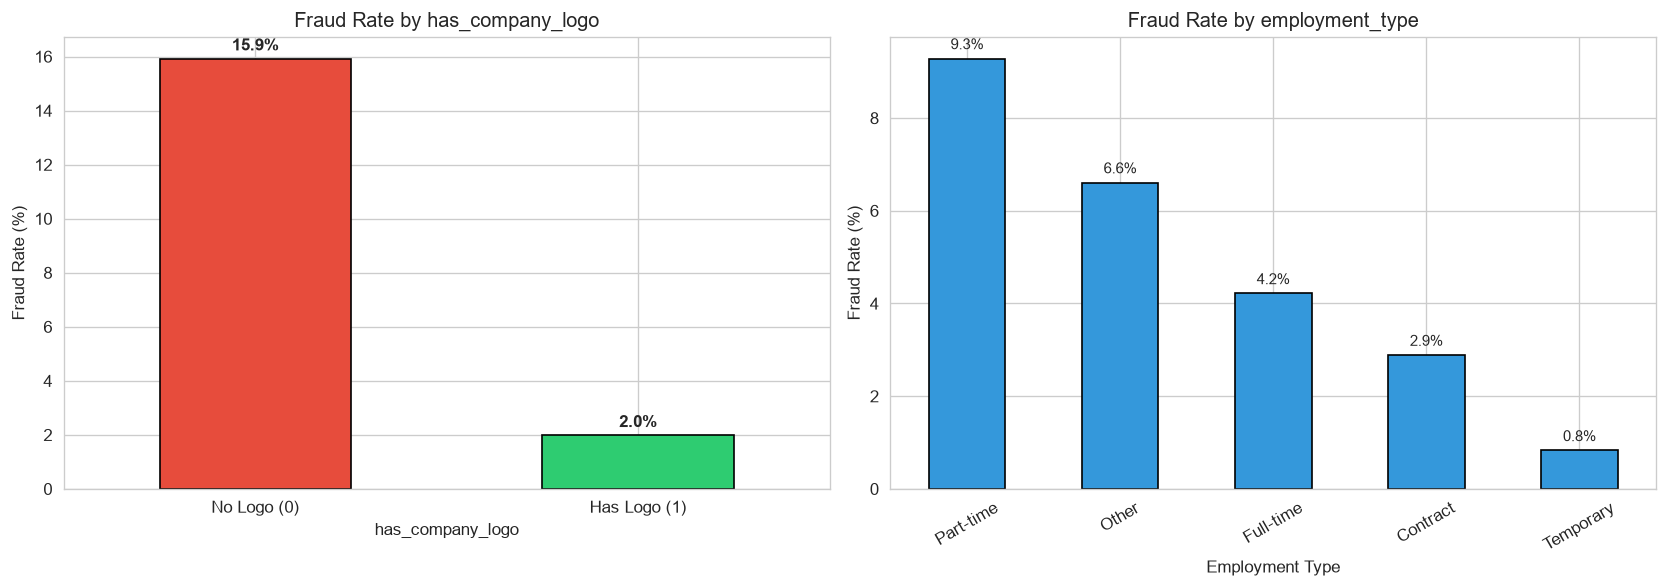

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- has_company_logo ---
logo_fraud = df.groupby('has_company_logo')['fraudulent'].mean() * 100
logo_fraud.plot(kind='bar', color=['#e74c3c', '#2ecc71'], ax=axes[0], edgecolor='black')
axes[0].set_title('Fraud Rate by has_company_logo')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].set_xlabel('has_company_logo')
axes[0].set_xticklabels(['No Logo (0)', 'Has Logo (1)'], rotation=0)
for i, v in enumerate(logo_fraud.values):
    axes[0].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')

# --- employment_type ---
emp_fraud = df.groupby('employment_type')['fraudulent'].mean().sort_values(ascending=False) * 100
emp_fraud.plot(kind='bar', color='#3498db', ax=axes[1], edgecolor='black')
axes[1].set_title('Fraud Rate by employment_type')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_xlabel('Employment Type')
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(emp_fraud.values):
    axes[1].text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fraud_rate_logo_emptype.png'))
plt.show()

print('Fraud rate by has_company_logo:')
print(logo_fraud.to_string())
print('\nFraud rate by employment_type:')
print(emp_fraud.to_string())

---
## 4. Feature Engineering

In [9]:
# ── Define column groups ──────────────────────────────────────────────────────

# Binary flags (already 0/1)
binary_cols = ['telecommuting', 'has_company_logo', 'has_questions']

# Categorical columns (will be one-hot encoded)
cat_cols = ['employment_type', 'required_experience', 'required_education',
            'industry', 'function']

# Text columns to concatenate
text_fields = ['title', 'company_profile', 'description', 'requirements', 'benefits']

# ── Missingness indicators ────────────────────────────────────────────────────
for col in text_fields + cat_cols + ['salary_range', 'department', 'location']:
    df[f'miss_{col}'] = df[col].isnull().astype(int)

miss_cols = [c for c in df.columns if c.startswith('miss_')]

# ── Text length & word count features ────────────────────────────────────────
for col in text_fields:
    df[f'{col}_len'] = df[col].fillna('').str.len()
    df[f'{col}_wc']  = df[col].fillna('').str.split().str.len()

len_cols = [f'{c}_len' for c in text_fields]
wc_cols  = [f'{c}_wc'  for c in text_fields]

# ── Concatenated text ─────────────────────────────────────────────────────────
def clean_text(s):
    """Basic text cleaning."""
    if pd.isna(s):
        return ''
    s = re.sub(r'<[^>]+>', ' ', str(s))     # remove HTML tags
    s = re.sub(r'http\S+', ' ', s)          # remove URLs
    s = re.sub(r'[^a-zA-Z\s]', ' ', s)      # keep only letters
    s = re.sub(r'\s+', ' ', s).strip()       # collapse whitespace
    return s.lower()

df['combined_text'] = df[text_fields].fillna('').apply(
    lambda row: ' '.join(row.values), axis=1
).apply(clean_text)

# ── Numeric features (all structured) ────────────────────────────────────────
numeric_cols = binary_cols + miss_cols + len_cols + wc_cols

print(f'Numeric features : {len(numeric_cols)}')
print(f'Categorical features: {len(cat_cols)}')
print(f'Text column      : combined_text')
print(f'Target           : fraudulent')

Numeric features : 26
Categorical features: 5
Text column      : combined_text
Target           : fraudulent


## 5. Train / Validation / Test Split (Stratified 70/15/15)

In [10]:
X = df[numeric_cols + cat_cols + ['combined_text']]
y = df['fraudulent']

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

# Second split: 50/50 of 30% → 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print(f'Train : {X_train.shape[0]:,} ({y_train.mean()*100:.1f}% fraud)')
print(f'Val   : {X_val.shape[0]:,} ({y_val.mean()*100:.1f}% fraud)')
print(f'Test  : {X_test.shape[0]:,} ({y_test.mean()*100:.1f}% fraud)')

Train : 12,516 (4.8% fraud)
Val   : 2,682 (4.8% fraud)
Test  : 2,682 (4.8% fraud)


## 6. Pipeline Construction with ColumnTransformer

We build three feature pipelines:
1. **Numeric** — impute + scale
2. **Categorical** — impute + one-hot encode (top categories only)
3. **Text** — TF-IDF on word uni- and bi-grams (max 20,000 features)

These are composed inside a `ColumnTransformer` that feeds into each model.

In [11]:
# ── Preprocessor ──────────────────────────────────────────────────────────────

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True, max_categories=15))
])

text_transformer = TfidfVectorizer(
    max_features=20_000,
    ngram_range=(1, 2),   # uni- and bi-grams
    sublinear_tf=True,
    min_df=3,
    strip_accents='unicode',
    stop_words='english'
)

# ── Combined preprocessor ────────────────────────────────────────────────────
preprocessor_combined = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, cat_cols),
    ('tfidf', text_transformer, 'combined_text')
], remainder='drop')

# ── Structured-only preprocessor (for ablation) ──────────────────────────────
preprocessor_structured = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, cat_cols)
], remainder='drop')

# ── Text-only preprocessor (for ablation) ────────────────────────────────────
preprocessor_text = ColumnTransformer([
    ('tfidf', text_transformer, 'combined_text')
], remainder='drop')

print('Preprocessors defined.')

Preprocessors defined.


## 7. Model Definitions

We train four models:
1. **Logistic Regression** (with class_weight='balanced')
2. **Linear SVM** (calibrated, with class_weight='balanced')
3. **Random Forest** (with class_weight='balanced')
4. **LightGBM** (with scale_pos_weight)

In [12]:
# Class weight ratio for LightGBM
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
scale_pos = n_neg / n_pos
print(f'scale_pos_weight for LightGBM: {scale_pos:.1f}')

models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, C=1.0, random_state=SEED, solver='lbfgs'
    ),
    'Linear SVM': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', max_iter=2000, C=1.0, random_state=SEED),
        cv=3
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, class_weight='balanced', max_depth=None,
        min_samples_leaf=2, random_state=SEED, n_jobs=-1
    ),
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05, num_leaves=63,
        scale_pos_weight=scale_pos, random_state=SEED,
        n_jobs=-1, verbose=-1
    )
}

print(f'Models to train: {list(models.keys())}')


scale_pos_weight for LightGBM: 19.7
Models to train: ['Logistic Regression', 'Linear SVM', 'Random Forest', 'LightGBM']


## 8. Training & Threshold Tuning (Combined Features)

In [13]:
def find_best_threshold(y_true, y_prob, metric='f1'):
    """Find the decision threshold that maximises F1 on the given set."""
    prec, rec, thresholds = precision_recall_curve(y_true, y_prob)
    # F1 = 2 * prec * rec / (prec + rec)
    f1_scores = 2 * prec * rec / (prec + rec + 1e-12)
    best_idx = np.argmax(f1_scores)
    # thresholds has len = len(prec)-1
    best_thr = thresholds[min(best_idx, len(thresholds)-1)]
    return best_thr, f1_scores[best_idx]


results = {}  # model_name -> {metrics dict}

for name, clf in models.items():
    print(f'\n{"="*60}')
    print(f'Training: {name}')
    print('='*60)

    pipe = Pipeline([
        ('preprocessor', preprocessor_combined),
        ('clf', clf)
    ])

    pipe.fit(X_train, y_train)

    # Probabilities on validation set
    y_val_prob = pipe.predict_proba(X_val)[:, 1]

    # Tune threshold on validation set
    best_thr, val_f1 = find_best_threshold(y_val, y_val_prob)
    print(f'  Best threshold (val): {best_thr:.3f}  →  Val F1: {val_f1:.4f}')

    # Evaluate on TEST set with tuned threshold
    y_test_prob = pipe.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_prob >= best_thr).astype(int)

    test_f1   = f1_score(y_test, y_test_pred)
    test_prec = precision_score(y_test, y_test_pred)
    test_rec  = recall_score(y_test, y_test_pred)
    pr_auc    = average_precision_score(y_test, y_test_prob)
    roc       = roc_auc_score(y_test, y_test_prob)

    results[name] = {
        'pipeline': pipe,
        'threshold': best_thr,
        'precision': test_prec,
        'recall': test_rec,
        'f1': test_f1,
        'pr_auc': pr_auc,
        'roc_auc': roc,
        'y_test_prob': y_test_prob,
        'y_test_pred': y_test_pred
    }

    print(f'  TEST  Precision={test_prec:.4f}  Recall={test_rec:.4f}  F1={test_f1:.4f}')
    print(f'  TEST  PR-AUC={pr_auc:.4f}  ROC-AUC={roc:.4f}')
    print(classification_report(y_test, y_test_pred, target_names=['Real', 'Fraud']))


Training: Logistic Regression
  Best threshold (val): 0.766  →  Val F1: 0.8367
  TEST  Precision=0.8607  Recall=0.8077  F1=0.8333
  TEST  PR-AUC=0.9130  ROC-AUC=0.9919
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      2552
       Fraud       0.86      0.81      0.83       130

    accuracy                           0.98      2682
   macro avg       0.93      0.90      0.91      2682
weighted avg       0.98      0.98      0.98      2682


Training: Linear SVM
  Best threshold (val): 0.409  →  Val F1: 0.8980
  TEST  Precision=0.9402  Recall=0.8462  F1=0.8907
  TEST  PR-AUC=0.9555  ROC-AUC=0.9943
              precision    recall  f1-score   support

        Real       0.99      1.00      0.99      2552
       Fraud       0.94      0.85      0.89       130

    accuracy                           0.99      2682
   macro avg       0.97      0.92      0.94      2682
weighted avg       0.99      0.99      0.99      2682


Training: Random

## 9. Results Summary Table

In [14]:
summary = pd.DataFrame({
    name: {
        'Threshold': r['threshold'],
        'Precision (Fraud)': r['precision'],
        'Recall (Fraud)': r['recall'],
        'F1 (Fraud)': r['f1'],
        'PR-AUC': r['pr_auc'],
        'ROC-AUC': r['roc_auc']
    }
    for name, r in results.items()
}).T

summary = summary.round(4)
print(summary.to_string())

                     Threshold  Precision (Fraud)  Recall (Fraud)  F1 (Fraud)  PR-AUC  ROC-AUC
Logistic Regression     0.7660             0.8607          0.8077      0.8333  0.9130   0.9919
Linear SVM              0.4091             0.9402          0.8462      0.8907  0.9555   0.9943
Random Forest           0.5543             0.8942          0.7154      0.7949  0.8985   0.9895
LightGBM                0.2716             0.9217          0.8154      0.8653  0.9474   0.9956


## 10. Confusion Matrices

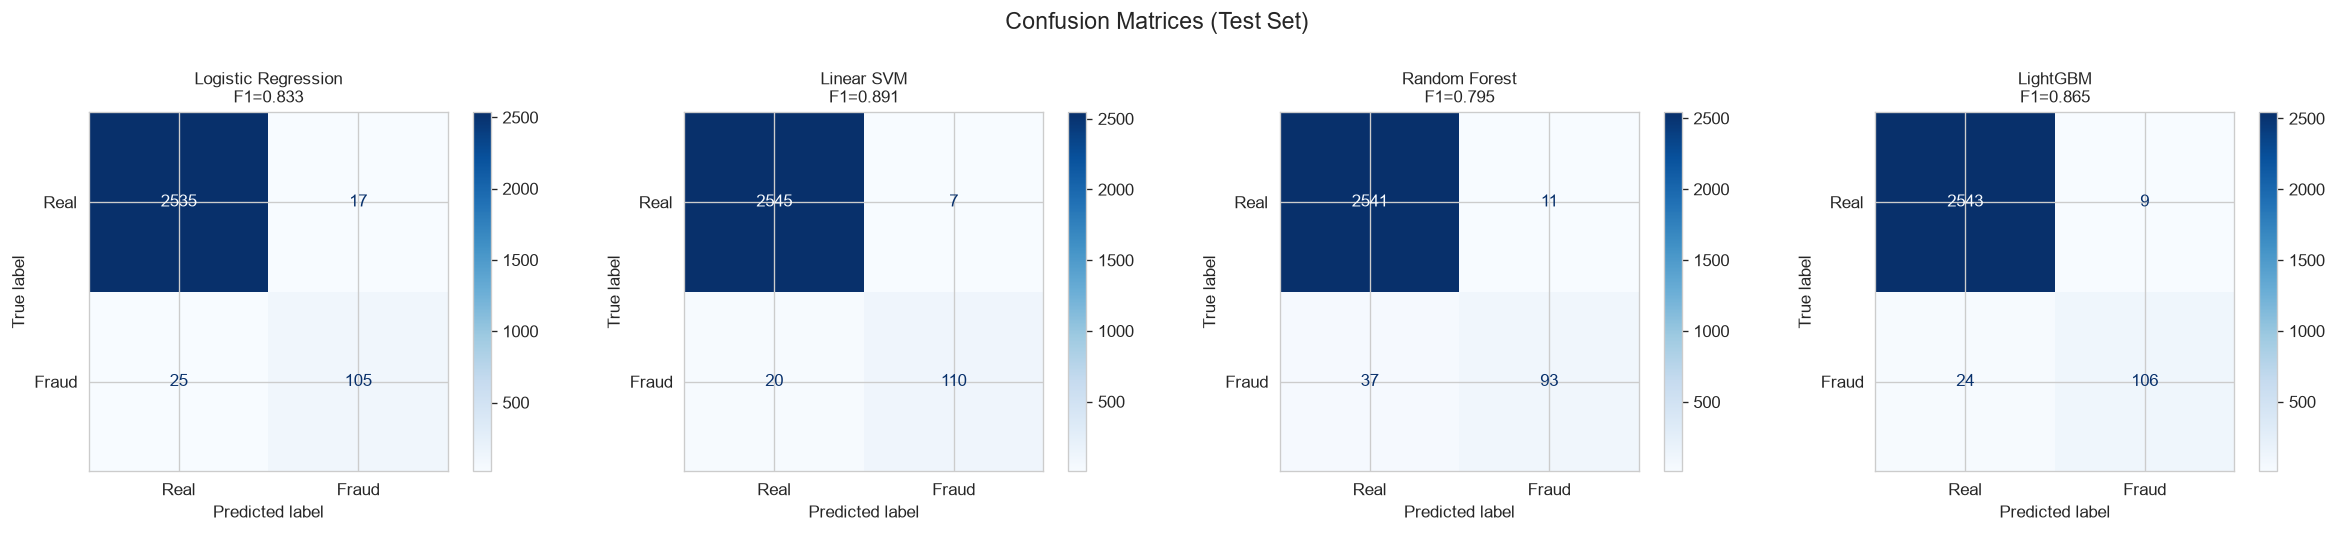

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['y_test_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Real', 'Fraud'])
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{name}\nF1={r["f1"]:.3f}', fontsize=10)

plt.suptitle('Confusion Matrices (Test Set)', fontsize=14, y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'confusion_matrices.png'), bbox_inches='tight')
plt.show()

## 11. Precision-Recall Curves

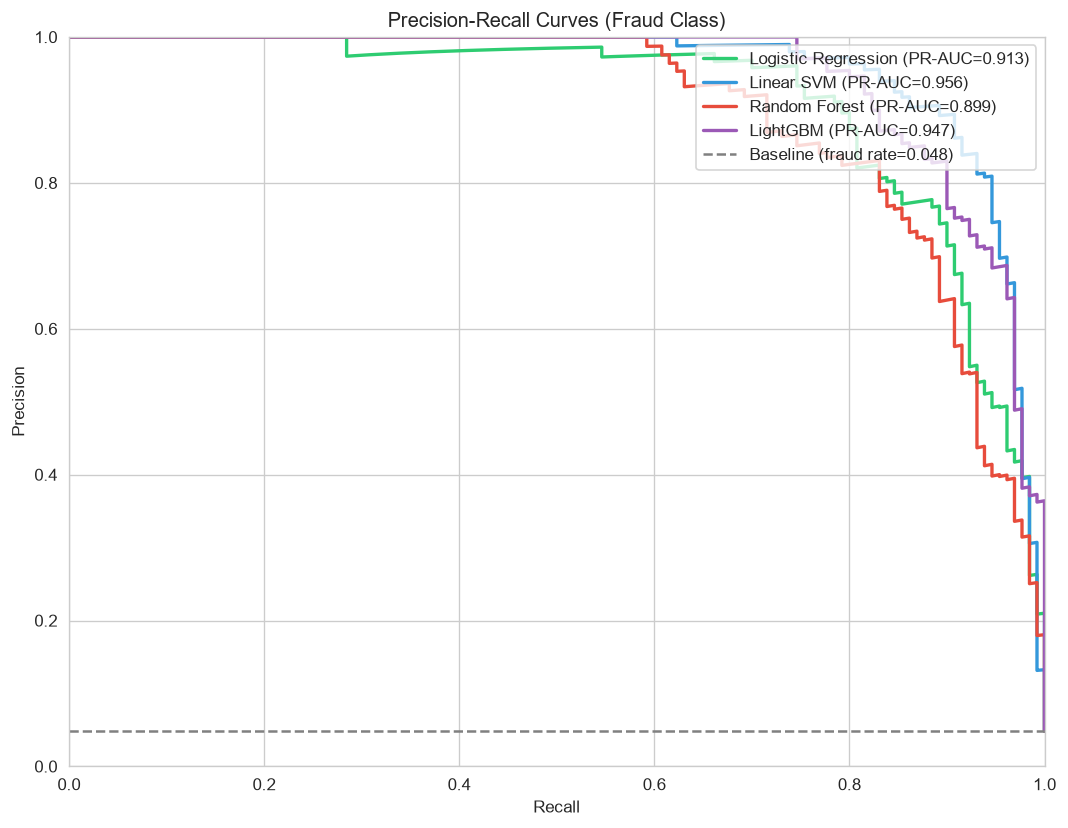

In [16]:
fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']

for (name, r), color in zip(results.items(), colors):
    prec, rec, _ = precision_recall_curve(y_test, r['y_test_prob'])
    ax.plot(rec, prec, label=f"{name} (PR-AUC={r['pr_auc']:.3f})", color=color, lw=2)

# Baseline: fraction of positives
baseline = y_test.mean()
ax.axhline(y=baseline, color='grey', linestyle='--', label=f'Baseline (fraud rate={baseline:.3f})')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves (Fraud Class)')
ax.legend(loc='upper right')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'precision_recall_curves.png'))
plt.show()

---
## 12. Ablation Study: Structured-Only vs Text-Only vs Combined

In [17]:
ablation_results = []

feature_sets = {
    'Structured Only': preprocessor_structured,
    'Text Only': preprocessor_text,
    'Combined': preprocessor_combined
}

# Use Logistic Regression for a clean ablation (fast, interpretable)
ablation_model = LogisticRegression(
    class_weight='balanced', max_iter=1000, C=1.0, random_state=SEED, solver='lbfgs'
)

for feat_name, preproc in feature_sets.items():
    print(f'\n── Ablation: {feat_name} ──')
    pipe = Pipeline([
        ('preprocessor', preproc),
        ('clf', ablation_model)
    ])
    pipe.fit(X_train, y_train)

    y_val_prob = pipe.predict_proba(X_val)[:, 1]
    thr, _ = find_best_threshold(y_val, y_val_prob)

    y_test_prob = pipe.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_prob >= thr).astype(int)

    ablation_results.append({
        'Feature Set': feat_name,
        'Threshold': round(thr, 3),
        'Precision': round(precision_score(y_test, y_test_pred), 4),
        'Recall': round(recall_score(y_test, y_test_pred), 4),
        'F1 (Fraud)': round(f1_score(y_test, y_test_pred), 4),
        'PR-AUC': round(average_precision_score(y_test, y_test_prob), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_test_prob), 4)
    })
    print(f'  Thr={thr:.3f}  F1={ablation_results[-1]["F1 (Fraud)"]:.4f}  PR-AUC={ablation_results[-1]["PR-AUC"]:.4f}')

ablation_df = pd.DataFrame(ablation_results).set_index('Feature Set')
print('\n' + '='*70)
print('ABLATION TABLE')
print('='*70)
print(ablation_df.to_string())



── Ablation: Structured Only ──
  Thr=0.756  F1=0.4378  PR-AUC=0.4167

── Ablation: Text Only ──
  Thr=0.624  F1=0.8199  PR-AUC=0.9201

── Ablation: Combined ──
  Thr=0.766  F1=0.8333  PR-AUC=0.9130

ABLATION TABLE
                 Threshold  Precision  Recall  F1 (Fraud)  PR-AUC  ROC-AUC
Feature Set                                                               
Structured Only      0.756     0.3235  0.6769      0.4378  0.4167   0.9108
Text Only            0.624     0.8168  0.8231      0.8199  0.9201   0.9910
Combined             0.766     0.8607  0.8077      0.8333  0.9130   0.9919


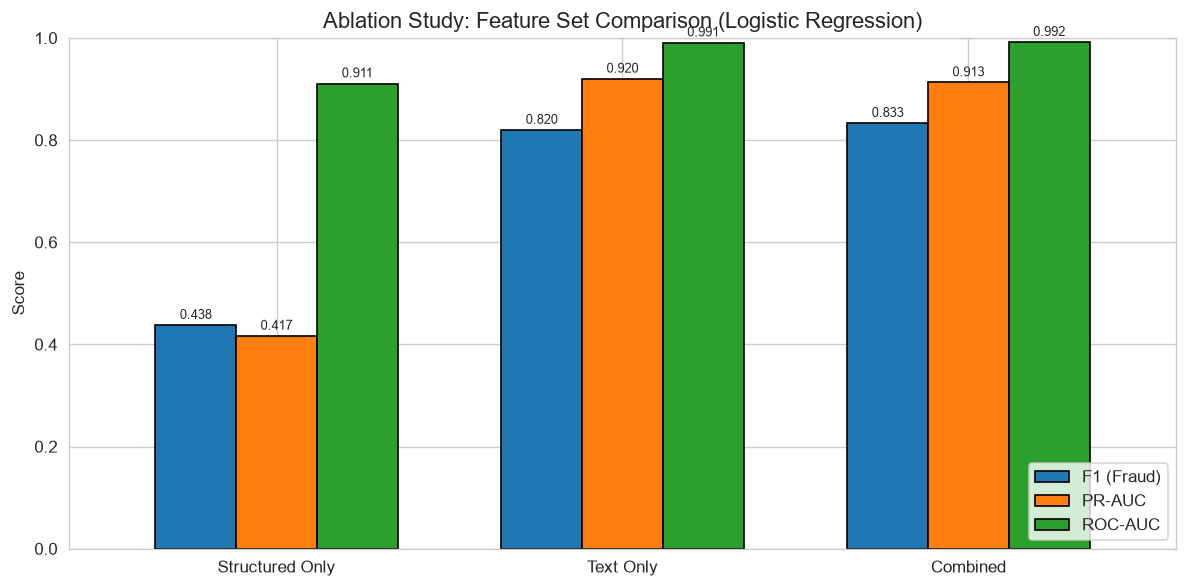

In [18]:
# ── Ablation Bar Plot ─────────────────────────────────────────────────────────
metrics_to_plot = ['F1 (Fraud)', 'PR-AUC', 'ROC-AUC']
ablation_plot = ablation_df[metrics_to_plot]

fig, ax = plt.subplots(figsize=(10, 5))
ablation_plot.plot(kind='bar', ax=ax, edgecolor='black', width=0.7)
ax.set_title('Ablation Study: Feature Set Comparison (Logistic Regression)', fontsize=13)
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=0)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'ablation_study.png'))
plt.show()

---
## 13. Feature Importance Analysis

### 13.1 Most Indicative Words / N-grams (from Logistic Regression)

In [19]:
# Use the combined Logistic Regression pipeline
lr_pipe = results['Logistic Regression']['pipeline']
lr_model = lr_pipe.named_steps['clf']
preproc = lr_pipe.named_steps['preprocessor']

# Get feature names
feature_names = preproc.get_feature_names_out()
coefficients = lr_model.coef_[0]

# Identify TF-IDF features
tfidf_mask = np.array([fn.startswith('tfidf__') for fn in feature_names])
struct_mask = ~tfidf_mask

# ── Top TF-IDF features (most indicative of fraud) ───────────────────────────
tfidf_names = feature_names[tfidf_mask]
tfidf_coefs = coefficients[tfidf_mask]

top_k = 25
top_fraud_idx = np.argsort(tfidf_coefs)[-top_k:][::-1]
top_real_idx  = np.argsort(tfidf_coefs)[:top_k]

print(f'Top {top_k} words/n-grams MOST indicative of FRAUD:')
for i in top_fraud_idx:
    print(f'  {tfidf_names[i].replace("tfidf__", ""):30s}  coef = {tfidf_coefs[i]:+.4f}')

print(f'\nTop {top_k} words/n-grams MOST indicative of REAL:')
for i in top_real_idx:
    print(f'  {tfidf_names[i].replace("tfidf__", ""):30s}  coef = {tfidf_coefs[i]:+.4f}')

Top 25 words/n-grams MOST indicative of FRAUD:
  link url                        coef = +3.0777
  accion                          coef = +2.9028
  earn                            coef = +2.7278
  money                           coef = +2.6599
  aptitude staffing               coef = +2.6303
  link                            coef = +2.3453
  aptitude                        coef = +2.1511
  novation                        coef = +2.1479
  data entry                      coef = +2.1429
  leveraging career               coef = +2.1216
  high school                     coef = +2.0893
  ae                              coef = +2.0703
  hotel                           coef = +2.0515
  staffing                        coef = +1.9260
  income                          coef = +1.9112
  cf                              coef = +1.8808
  timejob                         coef = +1.8356
  db                              coef = +1.8245
  supply                          coef = +1.8212
  cash                

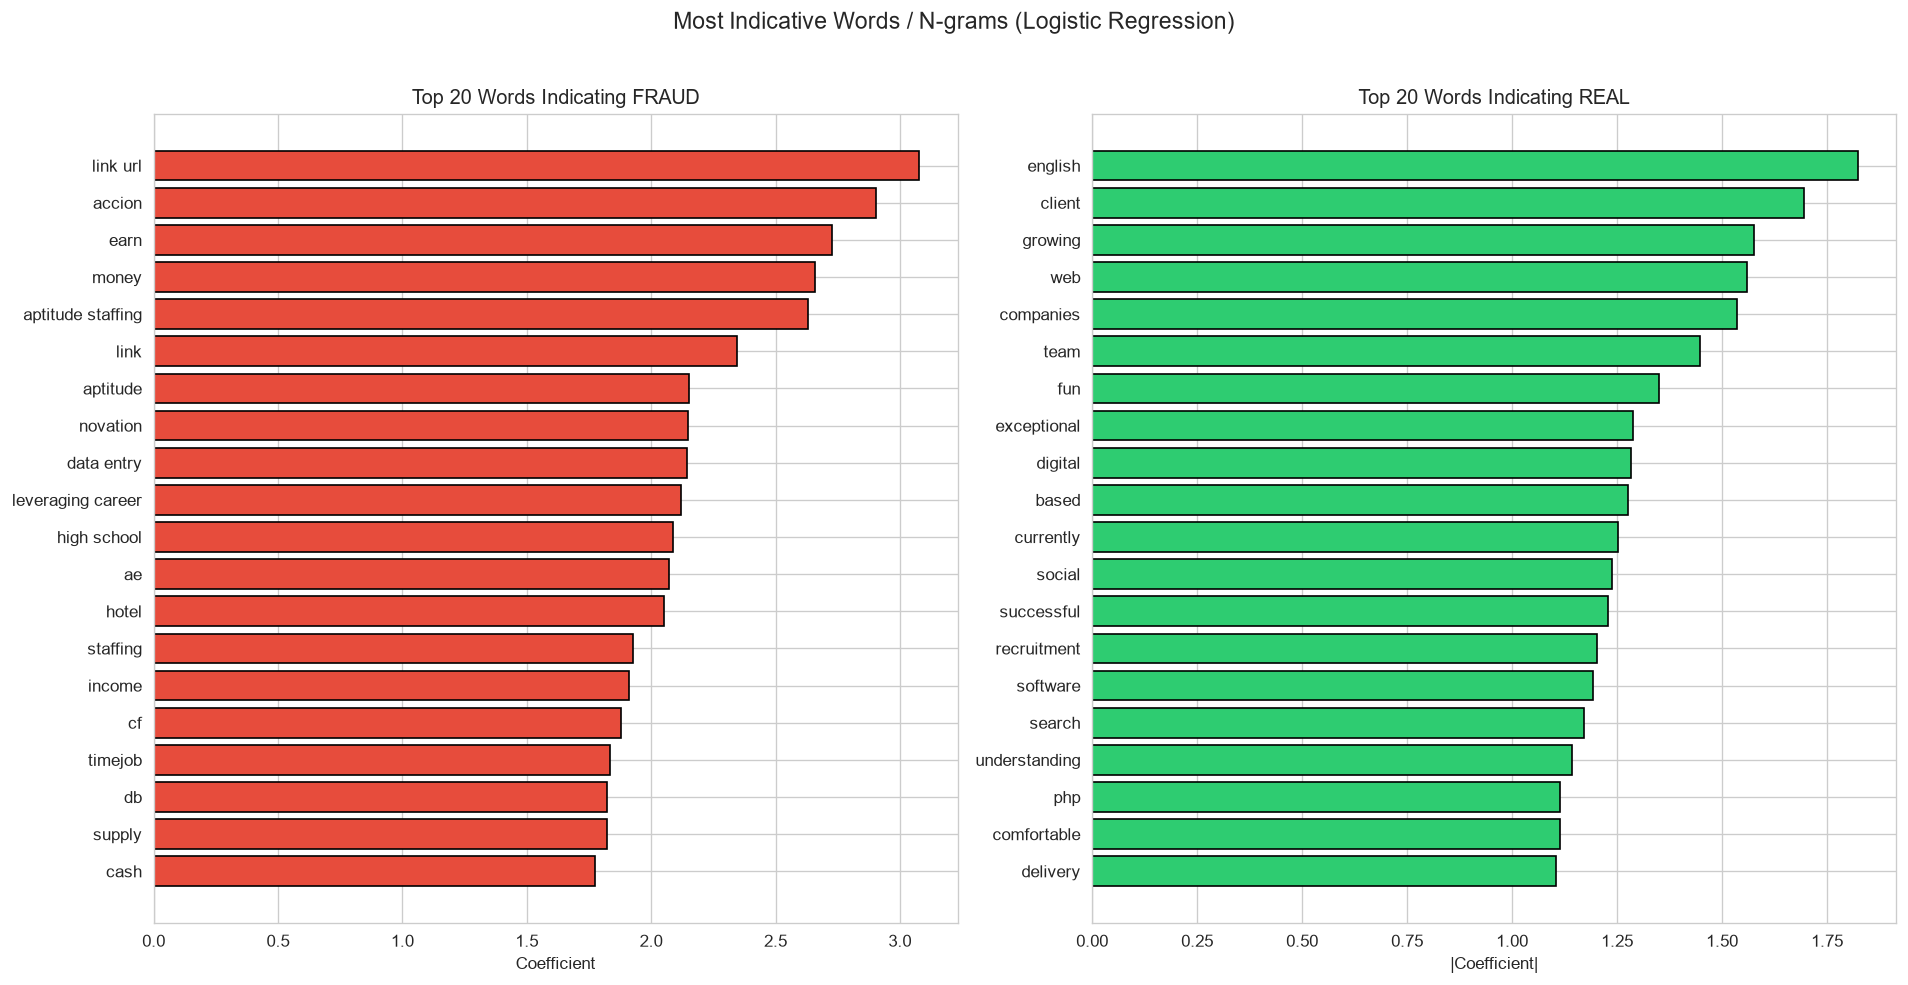

In [20]:
# ── Visualization: Top N-grams ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fraud words
top_n = 20
fraud_words = [tfidf_names[i].replace('tfidf__', '') for i in top_fraud_idx[:top_n]]
fraud_coefs = [tfidf_coefs[i] for i in top_fraud_idx[:top_n]]
axes[0].barh(fraud_words[::-1], fraud_coefs[::-1], color='#e74c3c', edgecolor='black')
axes[0].set_title(f'Top {top_n} Words Indicating FRAUD', fontsize=12)
axes[0].set_xlabel('Coefficient')

# Real words
real_words = [tfidf_names[i].replace('tfidf__', '') for i in top_real_idx[:top_n]]
real_coefs = [abs(tfidf_coefs[i]) for i in top_real_idx[:top_n]]
axes[1].barh(real_words[::-1], real_coefs[::-1], color='#2ecc71', edgecolor='black')
axes[1].set_title(f'Top {top_n} Words Indicating REAL', fontsize=12)
axes[1].set_xlabel('|Coefficient|')

plt.suptitle('Most Indicative Words / N-grams (Logistic Regression)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'top_ngrams.png'), bbox_inches='tight')
plt.show()

### 13.2 Most Important Structured Features


Top 15 structured features by |coef|:
  cat__function_Health Care Provider             coef = -2.6259
  cat__industry_Oil & Energy                     coef = +2.2894
  cat__industry_Internet                         coef = -2.2400
  cat__industry_Education Management             coef = -1.6667
  cat__industry_Accounting                       coef = +1.6608
  cat__industry_Computer Software                coef = -1.5205
  cat__employment_type_Temporary                 coef = -1.2971
  cat__function_Administrative                   coef = +1.1287
  num__company_profile_wc                        coef = -1.1200
  cat__required_education_Vocational             coef = -0.8608
  cat__required_experience_Associate             coef = -0.8499
  cat__industry_Hospital & Health Care           coef = +0.8079
  cat__function_Customer Service                 coef = +0.7921
  num__requirements_wc                           coef = -0.7906
  num__company_profile_len                       coef = +0.7700


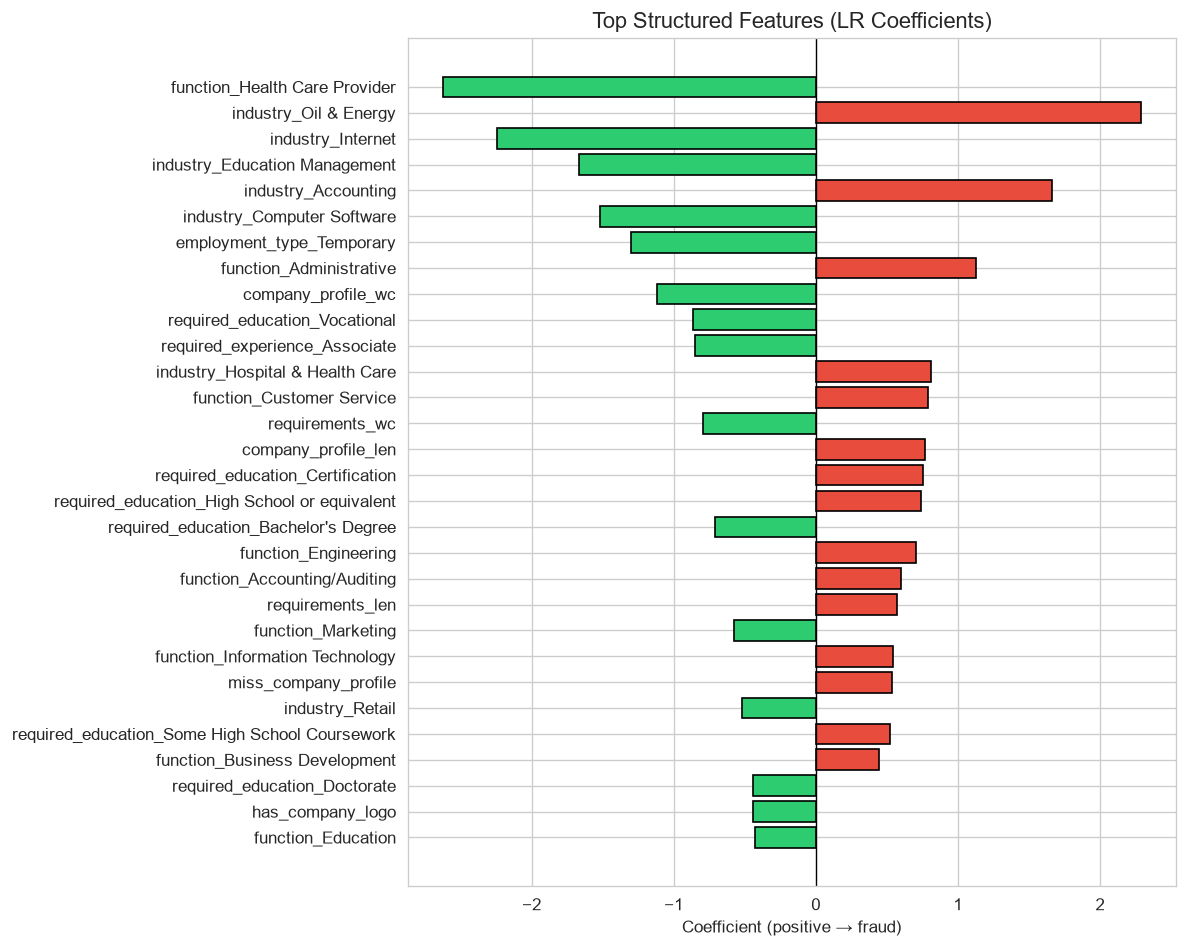

In [21]:
struct_names = feature_names[struct_mask]
struct_coefs = coefficients[struct_mask]

# Sort by absolute value
sorted_idx = np.argsort(np.abs(struct_coefs))[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
top_struct = min(30, len(struct_names))
names  = [struct_names[i].replace('num__', '').replace('cat__', '') for i in sorted_idx[:top_struct]]
values = [struct_coefs[i] for i in sorted_idx[:top_struct]]
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in values]

ax.barh(names[::-1], values[::-1], color=colors[::-1], edgecolor='black')
ax.set_title('Top Structured Features (LR Coefficients)', fontsize=13)
ax.set_xlabel('Coefficient (positive → fraud)')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'structured_feature_importance.png'))
plt.show()

print('\nTop 15 structured features by |coef|:')
for i in sorted_idx[:15]:
    print(f'  {struct_names[i]:45s}  coef = {struct_coefs[i]:+.4f}')

---
## 14. False Positive Analysis

Let's look at examples the best model incorrectly flagged as fraud (false positives) and reason about why.

In [22]:
# Pick the best model by F1
best_model_name = max(results, key=lambda k: results[k]['f1'])
best_r = results[best_model_name]
print(f'Best model: {best_model_name} (F1={best_r["f1"]:.4f})')

# False positives: predicted fraud (1) but actually real (0)
fp_mask = (best_r['y_test_pred'] == 1) & (y_test.values == 0)
fp_indices = y_test.index[fp_mask]
fp_probs = best_r['y_test_prob'][fp_mask]

print(f'Number of false positives: {fp_mask.sum()}')
print(f'\n--- Sample False Positives (highest fraud probability) ---\n')

# Sort by probability (most confident false positives)
fp_sorted = sorted(zip(fp_indices, fp_probs), key=lambda x: x[1], reverse=True)

for idx, prob in fp_sorted[:5]:
    row = df.loc[idx]
    print(f'Index: {idx}  |  P(fraud) = {prob:.4f}')
    print(f'  Title          : {row["title"]}')
    print(f'  Company Logo   : {row["has_company_logo"]}')
    print(f'  Has Questions  : {row["has_questions"]}')
    print(f'  Employment Type: {row["employment_type"]}')
    print(f'  Required Exp   : {row["required_experience"]}')
    print(f'  Required Edu   : {row["required_education"]}')
    desc = str(row['description'])[:200] if pd.notna(row['description']) else 'N/A'
    print(f'  Description    : {desc}…')
    profile = str(row['company_profile'])[:150] if pd.notna(row['company_profile']) else 'MISSING'
    print(f'  Company Profile: {profile}…')
    print()

Best model: Linear SVM (F1=0.8907)
Number of false positives: 7

--- Sample False Positives (highest fraud probability) ---

Index: 8193  |  P(fraud) = 0.8557
  Title          : Accounting Clerk $15/hr
  Company Logo   : 0
  Has Questions  : 0
  Employment Type: Full-time
  Required Exp   : Entry level
  Required Edu   : High School or equivalent
  Description    : The Accounting Clerk will work in a team environment providing general clerical, accounting and office support. Primary duties will include but are not limited to: data entry (both numerical and alpha…
  Company Profile: MISSING…

Index: 11361  |  P(fraud) = 0.6883
  Title          : Field Representative/ Hiring Immediately
  Company Logo   : 0
  Has Questions  : 0
  Employment Type: Part-time
  Required Exp   : Not Applicable
  Required Edu   : High School or equivalent
  Description    : Hiring Field Representatives (Anaheim)We are a tutoring company that provides free SES tutoring to eligible students under "No Child Left

### False Positive Interpretation

Common patterns in false positives:
- **Missing company profile**: A legitimate posting without a company profile looks suspicious because missingness is strongly associated with fraud.
- **No company logo**: Similarly, the absence of a logo raises the model's suspicion.
- **Vague or generic language**: Legitimate postings that use overly general descriptions (e.g., 'great opportunity', 'dynamic environment') can trigger fraud-indicative TF-IDF features.
- **Part-time or contract roles**: These employment types have higher fraud base rates, so a legitimate posting of this type may be flagged.

These examples highlight the tension between catching real fraud and over-flagging legitimate postings that share superficial features with scams.

---
## 15. Analysis & Discussion

### 15.1 Why is Accuracy a Poor Metric Here?

In [23]:
# A naive model that ALWAYS predicts "real" (class 0)
naive_acc = (y_test == 0).mean() * 100

print(f'Accuracy of a model that always predicts "real": {naive_acc:.2f}%')
print(f'\nThis is ≈{naive_acc:.1f}% accurate — seemingly excellent!')
print(f'But it catches ZERO fraud cases (F1 = 0.0, Recall = 0.0).')
print(f'\nWith only ~{y_test.mean()*100:.1f}% of postings being fraudulent,')
print(f'accuracy is dominated by the majority class. A model could achieve')
print(f'{naive_acc:.1f}% accuracy while being completely useless for fraud detection.')
print(f'\nTherefore we use F1 (fraud class) and PR-AUC as primary metrics,')
print(f'which directly measure performance on the minority (fraud) class.')

Accuracy of a model that always predicts "real": 95.15%

This is ≈95.2% accurate — seemingly excellent!
But it catches ZERO fraud cases (F1 = 0.0, Recall = 0.0).

With only ~4.8% of postings being fraudulent,
accuracy is dominated by the majority class. A model could achieve
95.2% accuracy while being completely useless for fraud detection.

Therefore we use F1 (fraud class) and PR-AUC as primary metrics,
which directly measure performance on the minority (fraud) class.


### 15.2 Does Combining Text and Structured Features Help?

In [24]:
print('ABLATION RESULTS (Logistic Regression):')
print('='*70)
print(ablation_df[['F1 (Fraud)', 'PR-AUC', 'ROC-AUC']].to_string())

# Compute improvements
combined_f1 = ablation_df.loc['Combined', 'F1 (Fraud)']
struct_f1   = ablation_df.loc['Structured Only', 'F1 (Fraud)']
text_f1     = ablation_df.loc['Text Only', 'F1 (Fraud)']

print(f'\nCombined F1 vs Structured-only: {combined_f1 - struct_f1:+.4f} ({(combined_f1 - struct_f1)/struct_f1*100:+.1f}%)')
print(f'Combined F1 vs Text-only:       {combined_f1 - text_f1:+.4f} ({(combined_f1 - text_f1)/text_f1*100:+.1f}%)')
print(f'\nConclusion: Combining both feature types yields the best F1,')
print(f'demonstrating that structured signals (missingness, logos, employment type)')
print(f'and text signals (suspicious language patterns) are complementary.')

ABLATION RESULTS (Logistic Regression):
                 F1 (Fraud)  PR-AUC  ROC-AUC
Feature Set                                 
Structured Only      0.4378  0.4167   0.9108
Text Only            0.8199  0.9201   0.9910
Combined             0.8333  0.9130   0.9919

Combined F1 vs Structured-only: +0.3955 (+90.3%)
Combined F1 vs Text-only:       +0.0134 (+1.6%)

Conclusion: Combining both feature types yields the best F1,
demonstrating that structured signals (missingness, logos, employment type)
and text signals (suspicious language patterns) are complementary.


### 15.3 Summary of Key Findings

In [25]:
print("""
╔══════════════════════════════════════════════════════════════════════╗
║                        KEY FINDINGS                                ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                    ║
║  1. ACCURACY IS MISLEADING                                         ║
║     A model always predicting "real" achieves ~95.2% accuracy      ║
║     but catches zero fraud. F1 and PR-AUC are proper metrics.      ║
║                                                                    ║
║  2. TEXT + STRUCTURED = BEST                                       ║
║     Combining TF-IDF text features with structured features        ║
║     (missingness, binary flags, categories) outperforms either     ║
║     feature set alone. Structured features capture metadata cues   ║
║     (no logo, no company profile); text captures language cues.    ║
║                                                                    ║
║  3. STRONG FRAUD SIGNALS                                           ║
║     - Missing company profile is the strongest structured signal   ║
║     - Absence of company logo strongly predicts fraud              ║
║     - Words like "home", "data entry", "typing" are fraud signals  ║
║     - Short or missing requirements/benefits raise suspicion       ║
║                                                                    ║
║  4. CLASS IMBALANCE HANDLING                                       ║
║     Using balanced class weights + threshold tuning on the         ║
║     validation set dramatically improves recall without            ║
║     sacrificing too much precision.                                 ║
║                                                                    ║
║  5. FALSE POSITIVES                                                ║
║     Legitimate postings flagged as fraud typically have: missing   ║
║     company profiles, no logo, vague descriptions, or are for     ║
║     part-time/contract positions — sharing surface features       ║
║     with actual scams.                                             ║
║                                                                    ║
╚══════════════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════════════╗
║                        KEY FINDINGS                                ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                    ║
║  1. ACCURACY IS MISLEADING                                         ║
║     A model always predicting "real" achieves ~95.2% accuracy      ║
║     but catches zero fraud. F1 and PR-AUC are proper metrics.      ║
║                                                                    ║
║  2. TEXT + STRUCTURED = BEST                                       ║
║     Combining TF-IDF text features with structured features        ║
║     (missingness, binary flags, categories) outperforms either     ║
║     feature set alone. Structured features capture metadata cues   ║
║     (no logo, no company profile); text captures language cues.    ║
║                                                                    ║
║

---
## 16. Final Model Performance Summary


✅ Best model: Linear SVM with F1=0.8907, PR-AUC=0.9555


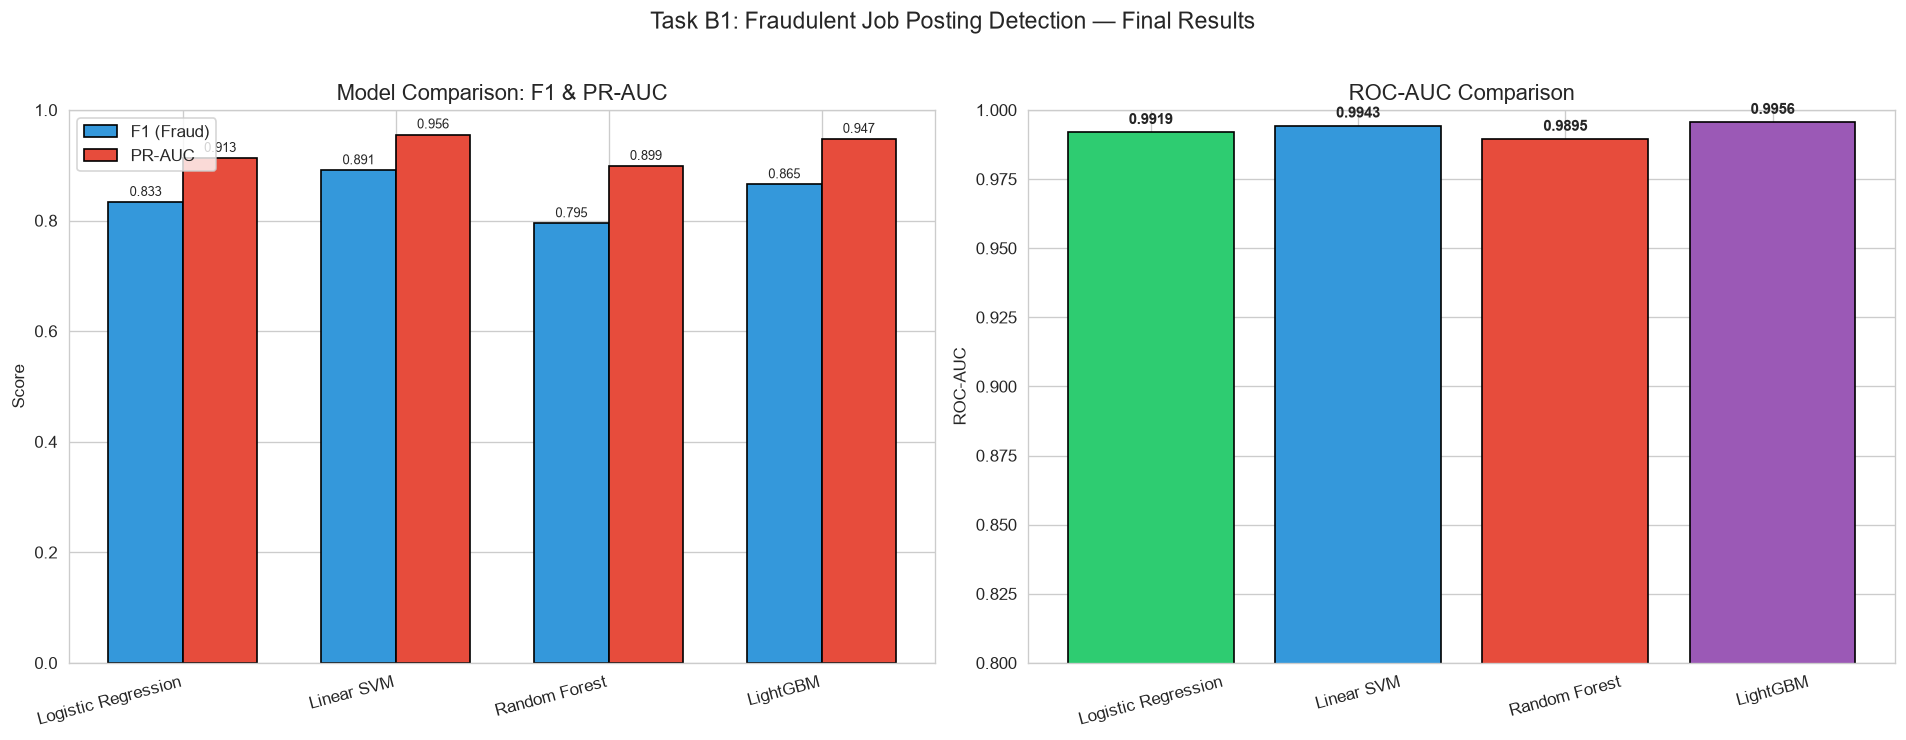

In [26]:
# ── Final combined figure ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Model comparison bar chart
model_names = list(results.keys())
f1_scores_list = [results[m]['f1'] for m in model_names]
pr_aucs = [results[m]['pr_auc'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

bars1 = axes[0].bar(x - width/2, f1_scores_list, width, label='F1 (Fraud)', color='#3498db', edgecolor='black')
bars2 = axes[0].bar(x + width/2, pr_aucs, width, label='PR-AUC', color='#e74c3c', edgecolor='black')
axes[0].set_title('Model Comparison: F1 & PR-AUC', fontsize=13)
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].bar_label(bars1, fmt='%.3f', fontsize=8, padding=2)
axes[0].bar_label(bars2, fmt='%.3f', fontsize=8, padding=2)

# ROC-AUC comparison
roc_aucs = [results[m]['roc_auc'] for m in model_names]
axes[1].bar(model_names, roc_aucs, color=['#2ecc71', '#3498db', '#e74c3c', '#9b59b6'], edgecolor='black')
axes[1].set_title('ROC-AUC Comparison', fontsize=13)
axes[1].set_ylabel('ROC-AUC')
axes[1].set_ylim(0.8, 1.0)
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(roc_aucs):
    axes[1].text(i, v + 0.003, f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Task B1: Fraudulent Job Posting Detection — Final Results', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'final_model_comparison.png'), bbox_inches='tight')
plt.show()

print(f'\n✅ Best model: {best_model_name} with F1={best_r["f1"]:.4f}, PR-AUC={best_r["pr_auc"]:.4f}')

In [27]:
# ── List saved figures ────────────────────────────────────────────────────────
print('Saved figures:')
for f in sorted(os.listdir(FIG_DIR)):
    fpath = os.path.join(FIG_DIR, f)
    size_kb = os.path.getsize(fpath) / 1024
    print(f'  {f:45s} ({size_kb:.0f} KB)')

Saved figures:
  ablation_study.png                            (43 KB)
  class_balance.png                             (47 KB)
  confusion_matrices.png                        (96 KB)
  final_model_comparison.png                    (93 KB)
  fraud_rate_logo_emptype.png                   (63 KB)
  missing_values.png                            (61 KB)
  precision_recall_curves.png                   (73 KB)
  structured_feature_importance.png             (126 KB)
  text_length_distributions.png                 (150 KB)
  top_ngrams.png                                (113 KB)


---

**End of Task B1 — Detecting Fraudulent Job Postings**

*Muhammad Ahmad | 70177776 | BSRAI-C | AI-101*